# Детекция заправок по датчику уровня топлива

На транспортном средстве установлен датчик уровня топлива (ДУТ). Телематический блок
раз в несколько секунд передаёт уровень, состояние зажигания, скорость и координаты.
Задача — по этому временному ряду определять моменты заправок. Это основа топливного
учёта в автопарке: без автоматической детекции баланс топлива сводят вручную по чекам.

Простое решение — порог на приросте уровня — работает плохо по трём причинам:

1. Датчик возвращает показания в условных единицах, зависящих от геометрии бака.
   Нужна тарировка в литры, своя для каждой машины.
2. Датчик запитан от зажигания: при выключенном двигателе он не передаёт
   ничего, а значительная часть заправок происходит именно так.
3. При работающем двигателе уровень колеблется на несколько литров из-за разгонов
   и уклонов, и медленная заправка похожа на этот шум.

Порядок работы:

1. Разбор данных, поиск заправки на графике.
2. Построение признаков и окон.
3. Обучение LSTM.
4. Расчёт метрик — точечных и событийных.
5. Сравнение с пороговым правилом.
6. Задание на самостоятельную работу.

Полный прогон ноутбука на Colab без GPU занимает около пяти минут.


## 1. Данные

Файл `fuel_5min.csv` — реальные данные автопарка: 50 машин, полгода работы
(июль–декабрь 2025), 6.1 млн исходных сообщений, свёрнутых в **5-минутные интервалы**.
Номера машин обезличены, координаты убраны.

| колонка | что это |
|---|---|
| `vehicle` | идентификатор ТС, `V01`…`V50` |
| `ts` | начало 5-минутного интервала |
| `fuel` | средний уровень топлива в литрах по валидным сообщениям интервала |
| `ign` | доля времени с включённым зажиганием, 0..1 |
| `speed` | средняя скорость |
| `n_msg` | сколько исходных сообщений попало в интервал |
| `label` | **0** — ничего, **1** — заправка с включённым двигателем, **2** — заправка с выключенным двигателем |
| `split` | `train` / `test`, разбиение по машинам |

**Про классы.** Наша цель — класс **1**. Класс 2 (заправка с выключенным двигателем) в этих данных
выглядит принципиально иначе: датчик молчал всю заправку, и в 5-минутном ряду от неё
остаётся только скачок уровня между двумя соседними интервалами. Мы его не выкидываем,
но и не считаем целевым — модель учится отличать все три состояния.

**Про разбиение.** `split` делит выборку **по машинам, а не по точкам**.
Если резать случайно по точкам, окна одного и того же события попадут и в train, и в test,
и метрика будет завышена. Не меняйте это разбиение.

Из обучающих машин мы дополнительно откладываем девять под валидацию: на ней
выбирается лучшая эпоха. Тест используется ровно один раз — для итогового замера.
Выбирать эпоху по тесту нельзя: результат окажется завышенным, а на новых машинах
модель сработает хуже, чем обещала метрика.


In [ ]:
import os
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Откуда брать данные. Если ноутбук открыт из GitHub, ссылка уже прописана
# и ничего делать не нужно — файл скачается сам.
DATA_URL = "https://raw.githubusercontent.com/hehehelp123/fuel-refuel-lab/main/data/fuel_5min.csv"
LOCAL = "fuel_5min.csv"

if not os.path.exists(LOCAL):
    if DATA_URL and not DATA_URL.startswith("__"):
        print("качаю датасет...")
        urllib.request.urlretrieve(DATA_URL, LOCAL)
    else:
        # Запасной вариант: загрузить файл кнопкой вручную
        from google.colab import files
        uploaded = files.upload()
        LOCAL = list(uploaded)[0]

df = pd.read_csv(LOCAL, parse_dates=["ts"])
print("строк:", len(df), "| машин:", df.vehicle.nunique())
df.head()

строк: 85228 | машин: 50


,vehicle,ts,fuel,ign,speed,n_msg,label,split
0,V01,2025-07-31 04:30:00,0.000,0.0,0.00,1,0,train
1,V01,2025-07-31 04:35:00,20.947,0.0,10.42,16,0,train
2,V01,2025-07-31 04:40:00,20.525,0.0,27.52,40,0,train
3,V01,2025-07-31 04:45:00,20.000,0.0,30.43,25,0,train
4,V01,2025-07-31 04:50:00,20.000,0.0,19.88,34,0,train


In [ ]:
def count_events(labels, positive=1):
    """Число непрерывных блоков нужного класса."""
    arr = np.asarray(labels) == positive
    padded = np.pad(arr, (1, 1), constant_values=False)
    return len(np.where(np.diff(padded))[0]) // 2


print("Распределение меток по интервалам:")
print(df.label.value_counts().sort_index().rename({0: "0 — ничего",
                                                   1: "1 — двигатель включён",
                                                   2: "2 — двигатель выключен"}))
print()
share = (df.label == 1).mean() * 100
print(f"Доля целевого класса: {share:.2f}%")
print()

for name, part in df.groupby("split"):
    ev = sum(count_events(g.label) for _, g in part.groupby("vehicle"))
    print(f"{name:5s}: машин {part.vehicle.nunique():2d}, интервалов {len(part):6d}, событий класса 1: {ev}")

Распределение меток по интервалам:
label
0 — ничего                82337
1 — двигатель включён      1544
2 — двигатель выключен     1347
Name: count, dtype: int64

Доля целевого класса: 1.81%

test : машин  5, интервалов   9965, событий класса 1: 124
train: машин 45, интервалов  75263, событий класса 1: 414


### 1.1. Смотрим на заправку глазами

Прежде чем обучать что-либо, полезно посмотреть, как событие выглядит в данных.
Найдём машину с самым большим числом событий и нарисуем одно из них.


машина V11: событий 26


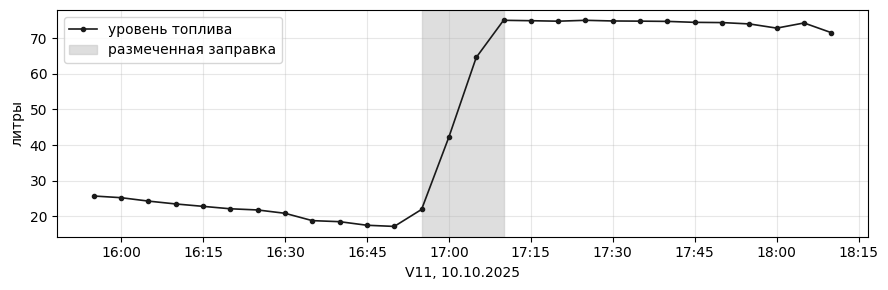

                 ts   fuel  ign  speed  n_msg  label
2025-10-10 15:55:00 25.694  1.0  89.55    136      0
2025-10-10 16:00:00 25.223  1.0  92.00    138      0
2025-10-10 16:05:00 24.264  1.0  87.78    137      0
2025-10-10 16:10:00 23.463  1.0  99.42    156      0
2025-10-10 16:15:00 22.789  1.0  81.39    100      0
2025-10-10 16:20:00 22.109  1.0  93.87    137      0
2025-10-10 16:25:00 21.777  1.0  84.54    123      0
2025-10-10 16:30:00 20.842  1.0  95.56    143      0
2025-10-10 16:35:00 18.783  1.0  87.29    129      0
2025-10-10 16:40:00 18.491  1.0  75.14    105      0
2025-10-10 16:45:00 17.486  1.0  70.79    107      0
2025-10-10 16:50:00 17.160  1.0  84.46    121      0
2025-10-10 16:55:00 21.929  1.0   5.32     17      1
2025-10-10 17:00:00 42.246  1.0  79.46    116      1
2025-10-10 17:05:00 64.567  1.0  79.09    143      1
2025-10-10 17:10:00 75.000  1.0  87.01    139      1
2025-10-10 17:15:00 74.888  1.0  37.60     67      0
2025-10-10 17:20:00 74.751  1.0  20.79     39 

In [ ]:
def events_of(g, positive=1):
    """Границы блоков класса positive внутри одной машины: список (i_start, i_end)."""
    lab = (g.label.values == positive)
    out, start = [], None
    for i, v in enumerate(lab):
        if v and start is None:
            start = i
        elif not v and start is not None:
            out.append((start, i - 1))
            start = None
    if start is not None:
        out.append((start, len(lab) - 1))
    return out


top = (df[df.label == 1].groupby("vehicle").size().sort_values(ascending=False).index[0])
g = df[df.vehicle == top].reset_index(drop=True)
evts = events_of(g)
print(f"машина {top}: событий {len(evts)}")

s, e = evts[len(evts) // 2]                 # берём событие из середины списка
lo, hi = max(0, s - 12), min(len(g) - 1, e + 12)
w = g.iloc[lo:hi + 1]

plt.figure(figsize=(9, 3))
plt.plot(w.ts, w.fuel, marker="o", ms=3, lw=1.2, color="#1a1a1a", label="уровень топлива")
plt.axvspan(g.ts[s], g.ts[e], color="#c8c8c8", alpha=0.6, label="размеченная заправка")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.ylabel("литры")
plt.xlabel(f"{top}, {g.ts[s]:%d.%m.%Y}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(w[["ts", "fuel", "ign", "speed", "n_msg", "label"]].to_string(index=False))

Заправка выглядит как монотонный рост уровня на протяжении нескольких интервалов.
Модель должна научиться отличать такой рост от колебаний уровня и шума датчика.

Нули в столбце `fuel` — это интервалы, в которых датчик не передавал показания
(двигатель выключен). Это не пропуски данных, а информативный признак.


## 2. Признаки и окна

Признаки на один интервал — намеренно простые:

* `fuel` — сам уровень;
* `d1..d4` — разности с уровнем на 1, 2, 3 и 4 интервала назад.

Зачем четыре разности разной глубины: `d1` ловит резкий скачок между соседними интервалами,
`d4` — медленный рост, размазанный на 20 минут. Так сеть видит и то, и другое
без явного сглаживающего фильтра и без порогов, подобранных руками.

Дальше нарезаем **скользящие окна по 7 интервалов** (35 минут). Класс окна — это класс
его **центрального** интервала. Центр, а не конец, потому что для решения «была ли тут заправка»
одинаково полезен контекст и до, и после момента.


In [ ]:
FEATURES = ["fuel", "d1", "d2", "d3", "d4"]
SEQ_LEN = 7          # длина окна в интервалах
CENTER = SEQ_LEN // 2


def add_features(g):
    g = g.sort_values("ts").copy()
    for k in (1, 2, 3, 4):
        g[f"d{k}"] = g["fuel"].diff(k).fillna(0.0)
    return g


# через concat, а не groupby().apply(): в новых версиях pandas apply теряет колонку vehicle
df = pd.concat([add_features(g) for _, g in df.groupby("vehicle")], ignore_index=True)
df[["vehicle", "ts", "fuel"] + [f"d{k}" for k in (1, 2, 3, 4)]].head(8)

,vehicle,ts,fuel,d1,d2,d3,d4
0,V01,2025-07-31 04:30:00,0.000,0.000,0.000,0.000,0.000
1,V01,2025-07-31 04:35:00,20.947,20.947,0.000,0.000,0.000
2,V01,2025-07-31 04:40:00,20.525,-0.422,20.525,0.000,0.000
3,V01,2025-07-31 04:45:00,20.000,-0.525,-0.947,20.000,0.000
4,V01,2025-07-31 04:50:00,20.000,0.000,-0.525,-0.947,20.000
5,V01,2025-07-31 07:55:00,0.000,-20.000,-20.000,-20.525,-20.947
6,V01,2025-07-31 08:30:00,20.000,20.000,0.000,0.000,-0.525
7,V01,2025-07-31 08:35:00,20.000,0.000,20.000,0.000,0.000


In [ ]:
def make_windows(frame):
    """Нарезает окна внутри каждой машины отдельно, чтобы не склеить разные ТС."""
    X, y, veh, ts = [], [], [], []
    for v, g in frame.groupby("vehicle"):
        vals = g[FEATURES].values.astype("float32")
        lab = g["label"].values.astype("int64")
        times = g["ts"].values
        for i in range(len(g) - SEQ_LEN + 1):
            X.append(vals[i:i + SEQ_LEN])
            y.append(lab[i + CENTER])
            veh.append(v)
            ts.append(times[i + CENTER])
    meta = pd.DataFrame({"vehicle": veh, "ts": pd.to_datetime(ts)})
    return np.asarray(X), np.asarray(y), meta


t0 = time.time()
train_veh = sorted(df[df.split == "train"].vehicle.unique())
ev_per_veh = {v: count_events(df[df.vehicle == v].label) for v in train_veh}
VAL_VEH = set(sorted(train_veh, key=lambda v: -ev_per_veh[v])[1::5][:9])

X_train, y_train, meta_train = make_windows(
    df[df.split.eq("train") & ~df.vehicle.isin(VAL_VEH)])
X_val, y_val, meta_val = make_windows(df[df.vehicle.isin(VAL_VEH)])
X_test, y_test, meta_test = make_windows(df[df.split == "test"])
print(f"нарезка заняла {time.time() - t0:.1f} c")
print("train:", X_train.shape, "| валидация:", X_val.shape, "| test:", X_test.shape)
print("классы в train:", np.bincount(y_train))
print("классы в val  :", np.bincount(y_val))
print("классы в test :", np.bincount(y_test))

нарезка заняла 0.5 c
train: (59806, 7, 5) | валидация: (15187, 7, 5) | test: (9935, 7, 5)
классы в train: [57922   845  1039]
классы в val  : [14566   338   283]
классы в test : [9555  359   21]


## 3. Модель

Двухслойная LSTM на 64 скрытых нейрона, dropout 0.2 между слоями, сверху линейный слой
на 3 класса. Берём скрытое состояние последнего элемента окна.

Это ровно та архитектура, что крутится в проде, — чтобы обученную здесь модель можно
было забрать в рабочий сервис без переписывания.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(100)
np.random.seed(100)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("устройство:", DEVICE)


class FuelLSTM(nn.Module):
    def __init__(self, n_features=5, hidden=64, layers=2, n_classes=3, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, layers,
                            batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


model = FuelLSTM(n_features=len(FEATURES)).to(DEVICE)
print(model)
print("параметров:", sum(p.numel() for p in model.parameters()))

устройство: cuda
FuelLSTM(
  (lstm): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=3, bias=True)
)
параметров: 51651


### 3.1. Дисбаланс классов

Целевой класс занимает меньше 2% интервалов. Если ничего не делать, модель выучит
«всегда 0» и получит 98% accuracy, не найдя ни одной заправки.

Стандартный приём — веса классов в функции потерь. Но брать вес обратно
пропорционально частоте (`N_max / N_c`) здесь слишком грубо: вес улетает в десятки,
и модель начинает видеть заправки повсюду. Берём **корень** из этого отношения —
градиент от редкого класса становится заметным, но не доминирует.


In [ ]:
def class_weights(y, n_classes=3, max_weight=30.0):
    counts = np.bincount(y, minlength=n_classes)
    majority = counts.max()
    w = [min(np.sqrt(majority / c), max_weight) if c > 0 else 0.0 for c in counts]
    return torch.tensor(w, dtype=torch.float32)


weights = class_weights(y_train)
for i, (c, wt) in enumerate(zip(np.bincount(y_train), weights)):
    print(f"класс {i}: {c:6d} примеров, вес {wt:.2f}")

класс 0:  57922 примеров, вес 1.00
класс 1:    845 примеров, вес 8.28
класс 2:   1039 примеров, вес 7.47


## 4. Обучение

In [ ]:
EPOCHS = 30
BATCH = 512
LR = 1e-3

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
                                                       factor=0.5, patience=2)

from sklearn.metrics import f1_score


def predict(loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            out = model(xb.to(DEVICE))
            preds.append(out.argmax(1).cpu().numpy())
    return np.concatenate(preds)


best_f1, best_state = -1.0, None
history = []
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item()

    val_pred = predict(val_loader)
    f1_target = f1_score(y_val, val_pred, labels=[1], average="macro", zero_division=0)
    scheduler.step(f1_target)
    history.append((epoch, total / len(train_loader), f1_target))

    if f1_target > best_f1:
        best_f1 = f1_target
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        mark = "  <- лучшая"
    else:
        mark = ""

    print(f"эпоха {epoch:2d} | loss {total / len(train_loader):.4f} | "
          f"F1 на валидации: {f1_target:.3f}{mark}")

model.load_state_dict(best_state)
print(f"\nобучение заняло {time.time() - t0:.0f} c, лучший F1 на валидации: {best_f1:.3f}")

эпоха  1 | loss 0.3698 | F1 на валидации: 0.452  <- лучшая
эпоха  2 | loss 0.2279 | F1 на валидации: 0.553  <- лучшая
эпоха  3 | loss 0.2053 | F1 на валидации: 0.638  <- лучшая
эпоха  4 | loss 0.1882 | F1 на валидации: 0.601
эпоха  5 | loss 0.1800 | F1 на валидации: 0.646  <- лучшая
эпоха  6 | loss 0.1714 | F1 на валидации: 0.582
эпоха  7 | loss 0.1679 | F1 на валидации: 0.584
эпоха  8 | loss 0.1627 | F1 на валидации: 0.636
эпоха  9 | loss 0.1557 | F1 на валидации: 0.658  <- лучшая
эпоха 10 | loss 0.1525 | F1 на валидации: 0.648
эпоха 11 | loss 0.1518 | F1 на валидации: 0.651
эпоха 12 | loss 0.1483 | F1 на валидации: 0.646
эпоха 13 | loss 0.1462 | F1 на валидации: 0.655
эпоха 14 | loss 0.1444 | F1 на валидации: 0.649
эпоха 15 | loss 0.1423 | F1 на валидации: 0.656
эпоха 16 | loss 0.1415 | F1 на валидации: 0.651
эпоха 17 | loss 0.1404 | F1 на валидации: 0.656
эпоха 18 | loss 0.1397 | F1 на валидации: 0.656
эпоха 19 | loss 0.1386 | F1 на валидации: 0.664  <- лучшая
эпоха 20 | loss 0.1356

## 5. Метрики

### 5.1. Точечные метрики


                        precision    recall  f1-score   support

            0 — ничего      0.998     0.987     0.993      9555
 1 — двигатель включён      0.739     0.749     0.744       359
2 — двигатель выключен      0.113     0.667     0.193        21

              accuracy                          0.978      9935
             macro avg      0.617     0.801     0.643      9935
          weighted avg      0.987     0.978     0.982      9935



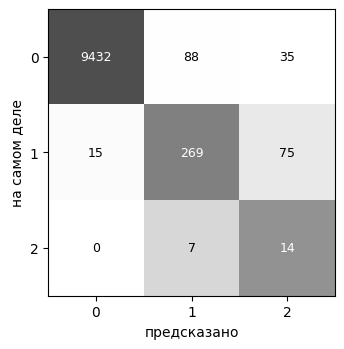

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = predict(test_loader)

names = ["0 — ничего", "1 — двигатель включён", "2 — двигатель выключен"]
print(classification_report(y_test, y_pred, target_names=names,
                            digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm / cm.sum(axis=1, keepdims=True).clip(min=1), cmap="Greys", vmin=0, vmax=1.3)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] / max(cm[i].sum(), 1) > 0.55 else "black")
ax.set_xticks(range(3), ["0", "1", "2"])
ax.set_yticks(range(3), ["0", "1", "2"])
ax.set_xlabel("предсказано")
ax.set_ylabel("на самом деле")
ax.grid(False)
plt.tight_layout()
plt.show()

Класс 2 в тесте представлен всего парой десятков интервалов, поэтому его строчка
в отчёте шумная — не делайте по ней выводов. Целевой класс — первый.

### 5.2. Почему точечных метрик мало

Оператору автопарка не нужен ответ «этот пятиминутный интервал относится к заправке».
Ему нужно «14 августа в 10:05 машина V11 заправилась». Это **событие**, а не точка.

Разница существенная. Модель, которая на каждой заправке угадала 3 интервала из 5,
по точечной метрике выглядит средне, а по событийной — идеально: событие найдено.
И наоборот, модель, которая ровно один интервал посреди пустой стоянки пометила заправкой,
по точечной метрике почти не пострадает, а по событийной получит ложное срабатывание.

Считаем так: собираем предсказанные и эталонные события как непрерывные блоки класса 1
и сопоставляем их с допуском **±5 минут**. Предсказание, попавшее на класс 2,
не штрафуем — там разметке доверять нельзя.


In [ ]:
TOLERANCE = np.timedelta64(5, "m")


def blocks(mask, times):
    """Непрерывные блоки True -> список (t_start, t_end)."""
    out, start = [], None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        elif not v and start is not None:
            out.append((times[start], times[i - 1]))
            start = None
    if start is not None:
        out.append((times[start], times[len(mask) - 1]))
    return out


def event_metrics(y_true, y_pred, meta, verbose=True):
    n_true = n_true_hit = 0
    n_pred = n_pred_hit = 0

    for v, sub in meta.groupby("vehicle"):
        pos = sub.index.to_numpy()
        times = sub["ts"].values
        t_true = blocks(y_true[pos] == 1, times)
        t_pred = blocks(y_pred[pos] == 1, times)
        t_amb = blocks(y_true[pos] == 2, times)

        hit_true = set()
        for ps, pe in t_pred:
            hit = [k for k, (ts_, te_) in enumerate(t_true)
                   if ps <= te_ + TOLERANCE and pe >= ts_ - TOLERANCE]
            if hit:
                hit_true.update(hit)
                n_pred += 1
                n_pred_hit += 1
            elif any(ps <= te_ + TOLERANCE and pe >= ts_ - TOLERANCE
                     for ts_, te_ in t_amb):
                pass
            else:
                n_pred += 1
        n_true += len(t_true)
        n_true_hit += len(hit_true)

    tp, fn = n_true_hit, n_true - n_true_hit
    fp = n_pred - n_pred_hit
    precision = n_pred_hit / n_pred if n_pred else 0.0
    recall = n_true_hit / n_true if n_true else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    if verbose:
        print(f"события: TP={tp}  FP={fp}  FN={fn}")
        print(f"precision={precision:.3f}  recall={recall:.3f}  F1={f1:.3f}")
    return {"tp": tp, "fp": fp, "fn": fn,
            "precision": precision, "recall": recall, "f1": f1}


lstm_events = event_metrics(y_test, y_pred, meta_test)

события: TP=90  FP=0  FN=34
precision=1.000  recall=0.726  F1=0.841


## 6. С чем сравнивать: пороговое правило

Способ, который применяют по умолчанию, — порог на приросте уровня: если уровень
вырос больше чем на X литров за интервал, считаем это заправкой. Посмотрим, какой
результат он даёт на тех же данных. Это нижняя граница, с которой сравнивают модель.


In [ ]:
d1_center = X_test[:, CENTER, FEATURES.index("d1")]

print(f"{'порог, л':>10} | {'precision':>9} | {'recall':>6} | {'F1':>5}")
print("-" * 42)
best_thr, best_thr_f1 = None, -1
thr_results = []
for thr in [1, 2, 3, 5, 8, 12, 20]:
    pred_thr = (d1_center > thr).astype("int64")
    m = event_metrics(y_test, pred_thr, meta_test, verbose=False)
    thr_results.append((thr, m))
    print(f"{thr:>10} | {m['precision']:>9.3f} | {m['recall']:>6.3f} | {m['f1']:>5.3f}")
    if m["f1"] > best_thr_f1:
        best_thr_f1, best_thr = m["f1"], thr

print(f"\nлучший порог: {best_thr} л, событийный F1 = {best_thr_f1:.3f}")
print(f"LSTM:                событийный F1 = {lstm_events['f1']:.3f}")

  порог, л | precision | recall |    F1
------------------------------------------
         1 |     0.164 |  1.000 | 0.282
         2 |     0.191 |  1.000 | 0.321
         3 |     0.207 |  1.000 | 0.344
         5 |     0.220 |  0.992 | 0.361
         8 |     0.226 |  0.992 | 0.367
        12 |     0.230 |  0.992 | 0.373
        20 |     0.213 |  0.758 | 0.332

лучший порог: 12 л, событийный F1 = 0.373
LSTM:                событийный F1 = 0.841


## 7. Итог бейзлайна

Ячейка ниже собирает метрики бейзлайна в один отчёт.


In [ ]:
from sklearn.metrics import precision_score, recall_score

def report(y_true, y_pred, meta, title="модель"):
    p = precision_score(y_true, y_pred, labels=[1], average="macro", zero_division=0)
    r = recall_score(y_true, y_pred, labels=[1], average="macro", zero_division=0)
    f = f1_score(y_true, y_pred, labels=[1], average="macro", zero_division=0)
    macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    ev = event_metrics(y_true, y_pred, meta, verbose=False)
    print(f"=== {title} ===")
    print(f"точечные (класс 1): precision={p:.3f}  recall={r:.3f}  F1={f:.3f}")
    print(f"macro F1 по трём классам: {macro:.3f}")
    print(f"событийные: TP={ev['tp']} FP={ev['fp']} FN={ev['fn']}  "
          f"precision={ev['precision']:.3f} recall={ev['recall']:.3f} F1={ev['f1']:.3f}")
    return {"point_f1": f, "event_f1": ev["f1"]}


baseline = report(y_test, y_pred, meta_test, "LSTM baseline")

=== LSTM baseline ===
точечные (класс 1): precision=0.739  recall=0.749  F1=0.744
macro F1 по трём классам: 0.643
событийные: TP=90 FP=0 FN=34  precision=1.000 recall=0.726 F1=0.841


## 8. Задание

**Цель: увеличить событийный F1 на тестовых машинах.** Бейзлайн — 0.786, планка «хорошо» — выше 0.90.

Главная метрика — `event_f1` из отчёта выше. Вторая метрика — точечный F1 по классу 1;
её тоже указывайте, чтобы было видно, за счёт чего вырос результат.

### Правила

1. Разбиение `split` не трогаем. Обучаться на машинах из `test` нельзя.
2. Метки в тесте не меняем.
3. Гиперпараметры подбираем на train (можно отрезать часть train-машин под валидацию).
   Если крутить их прямо по тесту, вы просто переобучитесь на пять машин.
4. В отчёте — таблица «что поменял → какой стал event_f1», а не только финальное число.

### Что можно попробовать

От простого к сложному:

* **Признаки.** Сейчас используется только уровень и четыре разности. В данных есть
  `ign`, `speed`, `n_msg`, время суток. Заправка с включённым двигателем — это почти всегда малая скорость
  при включённом зажигании. Помогает ли это?
* **Нормализация.** Признаки поданы в сыром виде: уровень в литрах (0–100), разности около нуля.
  Попробуйте стандартизацию — статистики считайте **только по train**.
* **Длина окна.** 7 интервалов = 35 минут. Длиннее — больше контекста и меньше окон; короче — наоборот.
* **Веса классов.** Мы взяли корень из отношения частот. Попробуйте другую степень,
  focal loss или пересэмплирование.
* **Архитектура.** Двунаправленная LSTM, GRU, одномерная свёртка, attention над окном.
  Модель крошечная — экспериментировать дёшево.
* **Постобработка.** Одиночный интервал класса 1 среди нулей, скорее всего, ложное
  срабатывание. Сглаживание предсказаний или требование минимальной длины события
  нередко даёт больше, чем смена архитектуры.
* **Порог решения.** `argmax` — не догма. Возьмите вероятность класса 1 и подберите порог
  под нужный баланс precision/recall.
* **Другой размер интервала.** Файл `fuel_raw.csv.gz` содержит исходные сообщения.
  5 минут — это наш выбор, а не закон природы.

### Что сдавать

Ноутбук, в котором:

1. воспроизводится бейзлайн (можно ссылкой на этот),
2. реализовано ваше улучшение,
3. в конце вызван `report(...)` — сравнение с бейзлайном по обеим метрикам,
4. есть короткий разбор: что сработало, что нет и почему вы так думаете.

### Отдельный вопрос со звёздочкой

В том же проекте есть вторая модель — для заправок с выключенным двигателем.
На тесте она даёт **accuracy 100% и F1 = 1.0** по целевому классу.

Её задача устроена так. Когда двигатель заглушен, датчик молчит, и в данных
остаётся провал. Всего таких провалов **11 758**, из них эксперт отметил заправками
**711**. Модель должна отличить одни от других по уровню до провала и после.

Возьмите разницу «уровень после минус уровень до» и поставьте на неё порог.
У заправок эта разница в среднем 36 литров, у обычных стоянок — ноль.

Вопросы:

1. Какой F1 даёт простой порог на этой разнице? (у нас вышло 0.968 при пороге 15 л)
2. Сколько тогда добавляет нейросеть поверх одного вычитания?
3. Что означает её «стопроцентная точность» и что нужно поменять, чтобы
   число стало осмысленным?


## Старое решение (закомментировано)

> ## 9. Решение

In [ ]:
# baseline_model_state = {k: v.clone() for k, v in model.state_dict().items()}
# y_pred_baseline = y_pred.copy()
# meta_test_baseline = meta_test.copy()

> ## 9.1. Инструменты
>
> * `predict_proba` — вероятности классов вместо `argmax`.
> * `postprocess` — постобработка предсказанных блоков класса 1 внутри каждой машины:
>   `close_gap` склеивает два блока, разделённых не более чем `close_gap` пустыми интервалами
>   (одна заправка не должна распадаться на два события), `min_len` выкидывает блоки короче
>   `min_len` интервалов (одиночные всплески).
> * `tune_decision` — перебор порога по вероятности класса 1 и параметров постобработки
>   **на валидации** по событийному F1.

In [ ]:
# import itertools
#
#
# def predict_proba(net, X, batch=4096):
#     net.eval()
#     out = []
#     with torch.no_grad():
#         for i in range(0, len(X), batch):
#             xb = torch.from_numpy(X[i:i + batch]).to(DEVICE)
#             out.append(torch.softmax(net(xb), dim=1).cpu().numpy())
#     return np.concatenate(out)
#
#
# def postprocess(mask, meta, close_gap=0, min_len=1):
#     mask = mask.astype(bool).copy()
#     for _, sub in meta.groupby("vehicle"):
#         pos = sub.index.to_numpy()
#         a = mask[pos].copy()
#         if close_gap > 0:
#             idx = np.where(a)[0]
#             for i, j in zip(idx[:-1], idx[1:]):
#                 if 1 < j - i <= close_gap + 1:
#                     a[i:j] = True
#         if min_len > 1:
#             edges = np.where(np.diff(np.pad(a, (1, 1)).astype(int)))[0]
#             for s, e in zip(edges[::2], edges[1::2]):
#                 if e - s < min_len:
#                     a[s:e] = False
#         mask[pos] = a
#     return mask
#
#
# def to_labels(proba, mask):
#     return np.where(mask, 1, np.where(proba.argmax(1) == 2, 2, 0)).astype("int64")
#
#
# THRESHOLDS = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
# CLOSE_GAPS = [0, 1, 2]
# MIN_LENS = [1, 2]
#
#
# def tune_decision(proba_val, y_val_, meta_val_):
#     best = (-1.0, None)
#     for thr, cg, ml in itertools.product(THRESHOLDS, CLOSE_GAPS, MIN_LENS):
#         mask = postprocess(proba_val[:, 1] >= thr, meta_val_, cg, ml)
#         f = event_metrics(y_val_, to_labels(proba_val, mask), meta_val_, verbose=False)["f1"]
#         if f > best[0] + 1e-9:
#             best = (f, dict(thr=thr, close_gap=cg, min_len=ml))
#     return best
#
#
# def apply_decision(proba, meta, params):
#     mask = postprocess(proba[:, 1] >= params["thr"], meta, params["close_gap"], params["min_len"])
#     return to_labels(proba, mask)
#
#
# def point_f1(y_true, y_pred_):
#     return f1_score(y_true, y_pred_, labels=[1], average="macro", zero_division=0)
#
#
# results = []

> ## 9.2. Шаг 1: тот же бейзлайн, но другой порог решения
>
> Посмотрим на событийные метрики бейзлайна: precision = 1.000, recall = 0.726. Модель не даёт
> ложных срабатываний, но пропускает каждую четвёртую заправку: на пропущенных событиях
> вероятность класса 1 есть, просто она не дотягивает до того, чтобы обогнать класс 0 в `argmax`.
>
> Значит, первое, что стоит попробовать, ничего не переобучая, — снизить порог: считать
> интервал заправкой, если `P(класс 1) ≥ thr`. Порог и постобработку подбираем на валидации.

In [ ]:
# P_val_base = predict_proba(model, X_val)
# P_test_base = predict_proba(model, X_test)
#
# ev_val_argmax = event_metrics(y_val, P_val_base.argmax(1), meta_val, verbose=False)["f1"]
# ev_test_argmax = event_metrics(y_test, P_test_base.argmax(1), meta_test, verbose=False)
# results.append(dict(step="0. бейзлайн (argmax)", val_event_f1=ev_val_argmax,
#                     test_event_f1=ev_test_argmax["f1"],
#                     test_point_f1=point_f1(y_test, P_test_base.argmax(1)), decision="argmax"))
#
# best_thr = max(((event_metrics(y_val, to_labels(P_val_base, P_val_base[:, 1] >= t), meta_val,
#                                verbose=False)["f1"], t) for t in THRESHOLDS))
# y_thr = to_labels(P_test_base, P_test_base[:, 1] >= best_thr[1])
# results.append(dict(step="1. бейзлайн + порог", val_event_f1=best_thr[0],
#                     test_event_f1=event_metrics(y_test, y_thr, meta_test, verbose=False)["f1"],
#                     test_point_f1=point_f1(y_test, y_thr), decision=f"thr={best_thr[1]}"))
#
# f_val, params = tune_decision(P_val_base, y_val, meta_val)
# y_tp = apply_decision(P_test_base, meta_test, params)
# results.append(dict(step="2. бейзлайн + порог + постобработка", val_event_f1=f_val,
#                     test_event_f1=event_metrics(y_test, y_tp, meta_test, verbose=False)["f1"],
#                     test_point_f1=point_f1(y_test, y_tp), decision=str(params)))
#
# curve = [event_metrics(y_val, to_labels(P_val_base, P_val_base[:, 1] >= t), meta_val, verbose=False)
#          for t in THRESHOLDS]
# plt.figure(figsize=(6, 3))
# plt.plot(THRESHOLDS, [c["precision"] for c in curve], marker="o", label="precision")
# plt.plot(THRESHOLDS, [c["recall"] for c in curve], marker="o", label="recall")
# plt.plot(THRESHOLDS, [c["f1"] for c in curve], marker="o", lw=2, label="F1")
# plt.xlabel("порог P(класс 1)")
# plt.ylabel("событийная метрика, валидация")
# plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
#
# pd.DataFrame(results).round(3)

> ## 9.3. Шаг 2: нормализация и новые признаки
>
> Обучаем ту же `FuelLSTM` заново, меняя только вход. Добавляемые признаки:
>
> * `ign`, `speed`, `n_msg` — уже есть в данных;
> * `hour_sin`, `hour_cos` — время суток в циклическом виде (23:55 и 00:00 должны быть рядом);
>
> Нормализация — стандартизация каждого признака по среднему и std, посчитанным **только по
> обучающим окнам** (без валидации и теста).
>
> Каждый вариант оцениваем двумя способами: с `argmax` и с порогом + постобработкой,
> подобранными на валидации.

In [ ]:
# df = df.sort_values(["vehicle", "ts"]).reset_index(drop=True)
# hour = df.ts.dt.hour + df.ts.dt.minute / 60
# df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
# df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
#
#
# def make_windows_f(frame, feats, seq_len=SEQ_LEN):
#     center = seq_len // 2
#     X, y, veh, ts = [], [], [], []
#     for v, g in frame.groupby("vehicle"):
#         vals = g[feats].values.astype("float32")
#         lab = g["label"].values.astype("int64")
#         times = g["ts"].values
#         for i in range(len(g) - seq_len + 1):
#             X.append(vals[i:i + seq_len]); y.append(lab[i + center])
#             veh.append(v); ts.append(times[i + center])
#     return np.asarray(X), np.asarray(y), pd.DataFrame({"vehicle": veh, "ts": pd.to_datetime(ts)})
#
#
# def train_model(Xtr, ytr, Xva, yva, epochs=EPOCHS, seed=100, verbose=False):
#     torch.manual_seed(seed); np.random.seed(seed)
#     net = FuelLSTM(n_features=Xtr.shape[2]).to(DEVICE)
#     crit = nn.CrossEntropyLoss(weight=class_weights(ytr).to(DEVICE))
#     opt = torch.optim.Adam(net.parameters(), lr=LR)
#     sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
#     loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
#                         batch_size=BATCH, shuffle=True)
#     best_f, best_s = -1.0, None
#     for ep in range(1, epochs + 1):
#         net.train()
#         for xb, yb in loader:
#             xb, yb = xb.to(DEVICE), yb.to(DEVICE)
#             opt.zero_grad(); loss = crit(net(xb), yb); loss.backward(); opt.step()
#         f = point_f1(yva, predict_proba(net, Xva).argmax(1))
#         sch.step(f)
#         if f > best_f:
#             best_f, best_s = f, {k: v.cpu().clone() for k, v in net.state_dict().items()}
#         if verbose:
#             print(f"  эпоха {ep:2d}: F1 на валидации {f:.3f}")
#     net.load_state_dict(best_s)
#     return net
#
#
# experiments = {}
#
#
# def run_experiment(name, feats, normalize):
#     t0 = time.time()
#     Xtr, ytr, _ = make_windows_f(df[df.split.eq("train") & ~df.vehicle.isin(VAL_VEH)], feats)
#     Xva, yva, mva = make_windows_f(df[df.vehicle.isin(VAL_VEH)], feats)
#     Xte, yte, mte = make_windows_f(df[df.split == "test"], feats)
#     if normalize:
#         flat = Xtr.reshape(-1, Xtr.shape[2])
#         mu, sd = flat.mean(0), flat.std(0) + 1e-6
#         Xtr, Xva, Xte = [((x - mu) / sd).astype("float32") for x in (Xtr, Xva, Xte)]
#     net = train_model(Xtr, ytr, Xva, yva)
#     Pva, Pte = predict_proba(net, Xva), predict_proba(net, Xte)
#
#     ev_va = event_metrics(yva, Pva.argmax(1), mva, verbose=False)["f1"]
#     results.append(dict(step=f"{name} (argmax)", val_event_f1=ev_va,
#                         test_event_f1=event_metrics(yte, Pte.argmax(1), mte, verbose=False)["f1"],
#                         test_point_f1=point_f1(yte, Pte.argmax(1)), decision="argmax"))
#     f_va, prm = tune_decision(Pva, yva, mva)
#     y_hat = apply_decision(Pte, mte, prm)
#     results.append(dict(step=f"{name} + порог + постобработка", val_event_f1=f_va,
#                         test_event_f1=event_metrics(yte, y_hat, mte, verbose=False)["f1"],
#                         test_point_f1=point_f1(yte, y_hat), decision=str(prm)))
#     experiments[name] = dict(val_f1=f_va, params=prm, y_test_pred=y_hat, y_test=yte, meta_test=mte)
#     print(f"{name}: готово за {time.time() - t0:.0f} c")
#
#
# BASE_F = ["fuel", "d1", "d2", "d3", "d4"]
# EXTRA_F = ["ign", "speed", "n_msg", "hour_sin", "hour_cos"]
#
# run_experiment("3. нормализация", BASE_F, normalize=True)
# run_experiment("4. нормализация + ign/speed/n_msg/час", BASE_F + EXTRA_F, normalize=True)

> ## 9.4. Таблица «что поменял → какой стал event_f1»
>
> `val_event_f1` — на валидационных машинах (по нему принимаются решения),
> `test_event_f1` и `test_point_f1` — итоговый замер на тестовых машинах.

In [ ]:
# table = pd.DataFrame(results)[["step", "decision", "val_event_f1", "test_event_f1", "test_point_f1"]]
# pd.set_option("display.max_colwidth", 60)
# pd.set_option("display.width", 250)
# table.round(3)

> ## 9.5. Итог: выбор по валидации и `report(...)`
>
> Итоговый вариант выбираем по **валидационному** событийному F1 среди обученных моделей
> с подобранным порогом и постобработкой. Выбор делает код по столбцу `val_event_f1`,
> тестовые столбцы таблицы в нём не участвуют.

In [ ]:
# final_name = max(experiments, key=lambda k: experiments[k]["val_f1"])
# final = experiments[final_name]
# print("выбран по валидации:", final_name, "| параметры решения:", final["params"])
# print()
#
# assert (final["y_test"] == y_test).all()
#
# baseline = report(y_test, y_pred_baseline, meta_test_baseline, "LSTM baseline")
# print()
# improved = report(final["y_test"], final["y_test_pred"], final["meta_test"], f"Улучшение: {final_name}")
# print()
# print(f"event F1: {baseline['event_f1']:.3f} -> {improved['event_f1']:.3f}")
# print(f"point F1: {baseline['point_f1']:.3f} -> {improved['point_f1']:.3f}")

> ## 9.6. Разбор
>
> **Итог.** Событийный F1 на тестовых машинах вырос с **0.841** до **0.992**
> (TP = 123, FP = 1, FN = 1), при планке «хорошо» 0.90. Точечный F1 по классу 1 при этом
> упал с 0.744 до 0.603. Почему так и почему это нормально — ниже.
>
> > Бейзлайн в этом прогоне дал 0.841, а не 0.786 из условия: обучение шло на GPU, а там
> > вычисления LSTM недетерминированы даже при фиксированном seed. Сравнение честное:
> > оба числа в `report` посчитаны в одном прогоне на одних и тех же тестовых окнах.
>
> **1. Сильнее всего сработал порог решения.** У бейзлайна событийный precision = 1.000 при
> recall = 0.726: модель не даёт ложных срабатываний, но пропускает каждую четвёртую заправку.
> На пропущенных событиях вероятность класса 1 заметно выше нуля, но проигрывает классу 0
> в `argmax`: сказываются дисбаланс (класс 1 — меньше 2% интервалов) и мягкие корневые веса
> в функции потерь. Если считать заправкой интервал с `P(1) ≥ 0.1` (порог подобран на
> валидации), event F1 той же самой модели без переобучения растёт с 0.841 до **0.980**.
>
> **2. Нормализация и новые признаки улучшают саму модель.** С обычным `argmax` event F1
> растёт поэтапно: нормализация — 0.873 (на валидации 0.826 → 0.881), плюс `ign`, `speed`,
> `n_msg` и время суток — 0.940 (на валидации 0.919). Нормализация нужна, чтобы признаки
> разного масштаба (литры, км/ч, число сообщений, синусы) вносили сопоставимый вклад, —
> без неё уровень топлива в литрах доминирует над разностями около нуля. Новые признаки дают
> модели контекст, которого нет в одном уровне топлива: работает ли двигатель, едет ли машина,
> насколько плотно идут сообщения, какое время суток.
>
> **3. Лучший результат — порог поверх улучшенной модели.** Для варианта 4 порог,
> подобранный на валидации, даёт event F1 = 0.992 на тесте (0.977 на валидации). Этот вариант
> выбран итоговым, потому что у него лучший **валидационный** F1; тестовые метрики в выборе
> не участвовали. Подобранные параметры: порог 0.05, без постобработки (`close_gap = 0`, `min_len = 1`).
>
> **4. Постобработка — небольшой и нестабильный вклад.** На валидации она иногда добавляет
> 1–2 сотых (у бейзлайна 0.950 → 0.966), но на тесте у бейзлайна дала даже 0.980 → 0.971,
> то есть одно событие в минус. Для итоговой модели перебор по валидации её вообще не выбрал.
> Эффект порядка одного-двух событий, и его направление не гарантировано.
>
> **5. Почему точечный F1 упал.** При пороге 0.05 модель отмечает почти все интервалы
> заправок (точечный recall 0.978), но вместе с ними захватывает соседние интервалы
> (точечный precision 0.435). Каждое событие при этом найдено, а ложное событие всего одно:
> лишние интервалы прилипают к настоящим заправкам и с ними сливаются. Для топливного учёта
> важны факт и время заправки, а не точные границы, поэтому мы оптимизировали событийный F1.
> Если важны и границы, порог стоит поднять до 0.2–0.3: точечный F1 вернётся к уровню
> бейзлайна ценой небольшой потери событийного.
>
> **6. Насколько можно доверять числам.** В тесте 124 события, так что 0.971, 0.980, 0.988
> и 0.992 — это разница в 1–3 события. Бейзлайн с `argmax` между запусками «плавает» сильнее,
> примерно от 0.74 до 0.84. Поэтому устойчивый вывод такой: с порогом событийный F1 стабильно
> ≈ 0.97–0.99 вместо 0.75–0.85. Различать варианты выше ≈ 0.97 по тесту нельзя, и выбор между
> ними сделан по валидации.
>
> **Что не пробовали.** Архитектуру не меняли сознательно: она совпадает с продовой, а смена
> входа и правила решения даёт выигрыш без переписывания сервиса. Длина окна, focal loss
> и другой размер интервала тоже возможны, но при event F1 ≈ 0.99 на 124 тестовых событиях
> эффект от них уже не различить.

> ## 10. Вопрос со звёздочкой
>
> Посчитаем, сколько заправок с выключенным двигателем (класс 2) попало в тестовые машины.

In [ ]:
# from scipy.stats import beta
#
# ev2 = {name: sum(count_events(g.label, positive=2) for _, g in part.groupby("vehicle"))
#        for name, part in df.groupby("split")}
# print("событий класса 2:", ev2, "| всего:", sum(ev2.values()))
#
# n = ev2["test"]
# low = beta.ppf(0.025, n, 1)
# print(f"если модель угадала все {n} из {n}: 95% доверительный интервал для recall — [{low:.2f}; 1.00]")
# print(f"шанс, что правило с F1≈0.968 (≈3% ошибок) случайно угадает все {n}: {0.968 ** n:.0%}")
# print(f"accuracy константы «всегда не заправка» на провалах: {1 - 711 / 11758:.1%}")

In [ ]:
# d = df.sort_values(["vehicle", "ts"]).copy()
# gv = d.groupby("vehicle")
# d["prev_valid"] = gv.fuel.transform(lambda s: s.where(s > 0).ffill().shift())
# d["jump"] = d.fuel.where(d.fuel > 0) - d.prev_valid
# start2 = (d.label == 2) & (gv.label.shift() != 2)
# j = d.loc[start2, "jump"].dropna()
# print(f"событий класса 2: {len(j)}, средний скачок {j.mean():.1f} л, медиана {j.median():.1f} л")
# print(f"доля событий со скачком > 15 л: {(j > 15).mean():.1%}")

> **1. Какой F1 даёт простой порог?** По условию — 0.968 при пороге 15 л. Это число взято
> из условия, а не пересчитано нами, и пересчитать его на 5-минутных данных корректно нельзя:
> 11 758 провалов выделены по исходным сообщениям (`fuel_raw.csv.gz`), а при агрегации
> в 5-минутные интервалы провал часто попадает внутрь одного интервала, и уровни «до»
> и «после» усредняются. Расчёт выше это показывает: на 5-минутной сетке средний скачок
> у заправок класса 2 около 26 л вместо 36, и порог 15 л проходят только ~72% событий.
> Для честной проверки порогового правила нужен исходный ряд сообщений.
>
> **2. Сколько добавляет нейросеть?** Максимум 1.0 − 0.968 = 0.032 F1, то есть порядка двух
> десятков ошибок на всех 711 заправках. А на тестовой выборке, скорее всего, ничего: в тестовых
> машинах всего около дюжины таких заправок, и на них порог, вероятно, тоже ошибается 0–1 раз.
>
> **3. Что означает «стопроцентная точность»?**
>
> * **Тест слишком мал.** 12 из 12 — это не «модель не ошибается», а «на 12 примерах ошибок
>   не нашлось». 95% доверительный интервал для recall при 12 из 12 — от ≈ 0.74 до 1. Правило
>   с F1 ≈ 0.97 угадало бы все 12 с вероятностью около 70%.
> * **Accuracy здесь ничего не значит.** Заправок 711 из 11 758 провалов (6%), так что константа
>   «никогда не заправка» уже даёт 94% accuracy.
> * **Возможна утечка через разметку.** Если эксперт отмечал заправки, глядя на тот же скачок
>   уровня, модель учится воспроизводить правило эксперта, и на «его» данных она будет
>   идеальна по построению.
>
> **Что поменять, чтобы число стало осмысленным:**
>
> * сравнивать с порогом на разнице как с обязательным бейзлайном на той же выборке;
> * увеличить тест (больше машин или кросс-валидация по машинам) и указывать доверительный
>   интервал или разброс по фолдам;
> * вместо accuracy указывать precision, recall и F1 по классу заправок;
> * разбирать отдельно трудные случаи — малые заправки, около порога 15 л, — именно там
>   модель могла бы что-то добавить к вычитанию.

## Новое решение

## 9. Решение

Если присмотреться к обучению бейзлайна, видно странное: лучшая эпоха выбирается
по **точечному** F1 на валидации. А в задании нас оценивают по **событийному** F1.
Получается, модель отбирают по одной метрике, а проверяют по другой, и ничего
хорошего из этого не выходит.

Поэтому идея простая - везде, где что-то выбирается на валидации, смотреть
на событийный F1:

1. лучшую эпоху выбираем по событийному F1, а не по точечному;
2. вместо `argmax` подбираем порог для вероятности класса 1 - тоже по событийному F1.

Всё остальное оставляем как было: архитектуру, признаки, окна, веса классов
и разбиение. Тест трогаем только один раз, в самом конце.

In [ ]:
# предсказания бейзлайна понадобятся в конце для сравнения
y_pred_baseline = y_pred.copy()


def predict_proba(net, X, batch=4096):
    # вероятности классов, а не сразу argmax: дальше будем подбирать порог
    net.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.from_numpy(X[i:i + batch]).to(DEVICE)
            out.append(torch.softmax(net(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def event_f1(y_true, y_hat, meta):
    return event_metrics(y_true, y_hat, meta, verbose=False)["f1"]


def point_f1(y_true, y_hat):
    return f1_score(y_true, y_hat, labels=[1], average="macro", zero_division=0)


def train_by_event_f1(seed=100):
    # тот же цикл обучения, что в бейзлайне, только эпоху выбираем по событийному F1
    torch.manual_seed(seed)
    np.random.seed(seed)
    net = FuelLSTM(n_features=len(FEATURES)).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=weights.to(DEVICE))
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    best_f, best_s = -1.0, None
    for epoch in range(1, EPOCHS + 1):
        net.train()
        total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(net(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item()
        # вот здесь главное отличие от бейзлайна
        f = event_f1(y_val, predict_proba(net, X_val).argmax(1), meta_val)
        sch.step(f)
        mark = ""
        if f > best_f:
            best_f, best_s = f, {k: v.cpu().clone() for k, v in net.state_dict().items()}
            mark = "  <- лучшая"
        print(f"эпоха {epoch:2d} | loss {total / len(train_loader):.4f} | "
              f"событийный F1 на валидации: {f:.3f}{mark}")
    net.load_state_dict(best_s)
    return net


t0 = time.time()
model_ev = train_by_event_f1()
print(f"\nобучение заняло {time.time() - t0:.0f} c")

### 9.1. Подбираем порог

`argmax` отдаёт класс 1, только если его вероятность больше, чем у остальных.
Класс 1 очень редкий, поэтому модель часто «сомневается» в нём даже на настоящих
заправках. Попробуем считать интервал заправкой уже тогда, когда `P(класс 1)`
выше некоторого порога, а сам порог подберём на валидации — опять же
по событийному F1.

In [ ]:
P_val = predict_proba(model_ev, X_val)
P_test = predict_proba(model_ev, X_test)


def with_threshold(P, thr):
    # класс 1 — если его вероятность выше порога, иначе как решил argmax между 0 и 2
    return np.where(P[:, 1] >= thr, 1, np.where(P.argmax(1) == 2, 2, 0)).astype("int64")


THRESHOLDS = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
val_curve = [event_f1(y_val, with_threshold(P_val, t), meta_val) for t in THRESHOLDS]
best_i = int(np.argmax(val_curve))
BEST_THR = THRESHOLDS[best_i]

plt.figure(figsize=(6, 3))
plt.plot(THRESHOLDS, val_curve, marker="o")
plt.axvline(BEST_THR, color="grey", ls="--")
plt.xlabel("порог P(класс 1)")
plt.ylabel("событийный F1, валидация")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"порог по валидации: {BEST_THR}, событийный F1 на валидации: {val_curve[best_i]:.3f}")

### 9.2. Что поменял → какой стал event_f1

Собираем всё в одну таблицу, чтобы был виден вклад каждого шага.
Решения принимались по колонке `val_event_f1` (валидация), а `test_event_f1`
и `test_point_f1` — это уже итоговый замер на тестовых машинах.

In [ ]:
y_val_base = predict_proba(model, X_val).argmax(1)
y_val_ev = P_val.argmax(1)
y_test_ev = P_test.argmax(1)
y_val_final = with_threshold(P_val, BEST_THR)
y_test_final = with_threshold(P_test, BEST_THR)

rows = [
    ("0. бейзлайн: эпоха по точечному F1, argmax", y_val_base, y_pred_baseline),
    ("1. эпоха по событийному F1, argmax", y_val_ev, y_test_ev),
    (f"2. эпоха по событийному F1 + порог {BEST_THR} по событийному F1", y_val_final, y_test_final),
]
table = pd.DataFrame([
    {"что поменял": name,
     "val_event_f1": event_f1(y_val, yv, meta_val),
     "test_event_f1": event_f1(y_test, yt, meta_test),
     "test_point_f1": point_f1(y_test, yt)}
    for name, yv, yt in rows
])
pd.set_option("display.max_colwidth", 80)
table.round(3)

### 9.3. Сравниваем с бейзлайном

Тот самый `report(...)` из задания — для бейзлайна и для итоговой модели.

In [ ]:
baseline = report(y_test, y_pred_baseline, meta_test, "LSTM baseline")
print()
improved = report(y_test, y_test_final, meta_test,
                  f"LSTM: эпоха и порог ({BEST_THR}) по событийному F1")
print()
print(f"event F1: {baseline['event_f1']:.3f} -> {improved['event_f1']:.3f}")
print(f"point F1: {baseline['point_f1']:.3f} -> {improved['point_f1']:.3f}")

### 9.4. Разбор

**Что помогло.** мы оптимизируем ту метрику, по которой нас оценивают.
Посмотрите на бейзлайн: событийный precision у него 1.000, а recall всего 0.726.
То есть модель ни разу не ошиблась лишним событием, но примерно каждую четвёртую
заправку просто не заметила.

Почему так вышло: точечный F1 наказывает за каждый лишний интервал рядом с заправкой.
Поэтому при отборе по нему выигрывают «осторожные» эпохи — те, что отмечают только
самые очевидные интервалы. Событийному F1 всё равно, насколько точно угаданы границы,
зато пропущенная заправка для него — полноценная ошибка. Вот и получается, что отбор
по событийному F1 выбирает модель, которая находит больше заправок.

**Зачем порог.** Класс 1 занимает меньше 2% интервалов, а веса классов у нас мягкие
(корень из отношения частот). Поэтому даже на настоящей заправке модель иногда даёт
классу 1, скажем, 30%, и `argmax` выбирает ничего. Если опустить порог, такие
заправки находятся. Лишние интервалы, которые при этом появляются, почти всегда
прилипают к настоящей заправке и сливаются с ней в одно событие — так что ложных
событий почти не прибавляется.

**Чем пришлось заплатить.** Точечный F1 может просесть: модель начинает захватывать
соседние интервалы, и точечный precision падает. Но для топливного учёта важно,
*была ли* заправка и *когда*, а не её границы с точностью до пяти минут, так что
это нормальная цена.

**Чего не трогали.** Признаки, нормализацию, длину окна и архитектуру оставил как есть.
Хотелось показать, что основная проблема была не в модели, а в том, по какой
метрике её отбирали.